# Experiment 1: Seed-informativeness sweep

| Setting | Definite mass | Definite background |
| --- | --- | --- |
| band 6/10 (default) | mask eroded up to 6 px (never erased: a small core is kept) | outside mask dilated 10 px |
| band 12/20 | eroded 12 | dilated 20 |
| band 20/30 | eroded 20 | dilated 30 |
| band 30/45 | eroded 30 | dilated 45 |
| click + loose box | a 4 px disc at the mask's deepest point | outside the mask bounding box grown by 10 px |

In [ ]:
# Imports and config
!pip install -q opencv-python scikit-learn scipy tqdm joblib

import os, json, random, warnings, math, time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm
from numpy.lib.stride_tricks import sliding_window_view
from scipy import ndimage
from scipy.sparse import csr_matrix, diags, identity
from scipy.sparse.linalg import spsolve
from scipy.spatial.distance import cdist
from scipy.ndimage import distance_transform_edt
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

K_FIXED = 8                             
DRIVE_ROOT = "/content/drive/MyDrive/mias_grc_project_v3_cv"
CONFIG = json.load(open(os.path.join(DRIVE_ROOT, "config.json")))
globals().update(CONFIG)
SEED = CONFIG["SEED"]; random.seed(SEED); np.random.seed(SEED)
LAP_WINDOW, LAP_EPSILON, MU_GRID, N_BOOT = 3, 1e-7, [0.1, 1.0, 10.0], 2000
OUT_DIR = os.path.join(RESULTS_DIR, f"K{K_FIXED}")
summ = json.load(open(os.path.join(OUT_DIR, "run_summary.json")))
assert summ['K'] == K_FIXED, "K_FIXED differs from the value used in Notebook 2"
L5_VARIANT = summ['layer5_variant']; L5_PLAIN = L5_VARIANT.replace('hybrid', 'plain')
print(f"Config loaded. K = {K_FIXED}, Layer 5 variant (from Notebook 2) = {L5_VARIANT}")

Mounted at /content/drive
Config loaded. K = 8, Layer 5 variant (from Notebook 2) = paper_hybrid_mu1


In [ ]:
final_df = pd.read_csv(os.path.join(RESULTS_DIR, "final_df_loaded.csv"))
roi_arch, gt_arch = np.load(os.path.join(PREPROCESSED_DIR, "rois.npz")), np.load(os.path.join(PREPROCESSED_DIR, "gt_masks.npz"))
oof = np.load(os.path.join(OUT_DIR, "oof_prob_maps.npz"))
class_of, patient_of = dict(zip(final_df['image_id'], final_df['class'])), dict(zip(final_df['image_id'], final_df['patient_id']))
FOLDS = json.load(open(os.path.join(RESULTS_DIR, "folds.json")))['folds']
EVAL_TEST = sorted(final_df['image_id']); assert set(oof.files) == set(EVAL_TEST), "an out-of-fold probability map is missing"
layer4_maps = {i: oof[i] for i in oof.files}
preprocessed_results = {i: {'roi': roi_arch[i].astype(np.float32), 'gt_mask': gt_arch[i], 'class': class_of[i], 'patient_id': patient_of[i]} for i in EVAL_TEST}
L5_MAIN = L5_VARIANT
print(f"{len(EVAL_TEST)} images, each with an out-of-fold probability map")

55 images, each with an out-of-fold probability map


## Layer 5 and metrics 

In [ ]:
def _downscale_trimap(trimap, hs, ws):
    h0, w0 = trimap.shape
    tm_s = cv2.resize(trimap, (ws, hs), interpolation=cv2.INTER_NEAREST)
    fg0 = np.argwhere(trimap == 255)
    if len(fg0) and not (tm_s == 255).any():
        cy, cx = fg0.mean(axis=0)
        tm_s[min(hs - 1, int(cy * hs / h0)), min(ws - 1, int(cx * ws / w0))] = 255
    return tm_s

def build_matting_laplacian(feat, win=LAP_WINDOW, eps=LAP_EPSILON):
    h, w = feat.shape; n = h * w; k = win * win
    idx = np.arange(n).reshape(h, w)
    iw = sliding_window_view(idx, (win, win)).reshape(-1, k)
    fw = sliding_window_view(feat.astype(np.float64), (win, win)).reshape(-1, k)
    mu = fw.mean(axis=1, keepdims=True)
    var = fw.var(axis=1, keepdims=True) + eps / k
    d = fw - mu
    W = (1.0 + d[:, :, None] * d[:, None, :] / var[:, :, None]) / k
    vals = np.eye(k)[None] - W
    rows = np.repeat(iw[:, :, None], k, axis=2).ravel()
    cols = np.repeat(iw[:, None, :], k, axis=1).ravel()
    return csr_matrix((vals.ravel(), (rows, cols)), shape=(n, n))

def _laplacian_loop(feat, win=LAP_WINDOW, eps=LAP_EPSILON):     
    h, w = feat.shape; n = h * w; half = win // 2; idx = np.arange(n).reshape(h, w)
    rows, cols, vals = [], [], []
    for i in range(half, h - half):
        for j in range(half, w - half):
            wi = idx[i-half:i+half+1, j-half:j+half+1].ravel()
            wf = feat[i-half:i+half+1, j-half:j+half+1].ravel().astype(np.float64)
            k = len(wf); var = wf.var() + eps / k; df = (wf - wf.mean()).reshape(-1, 1)
            Wm = (1.0 + (df @ df.T) / var) / k
            for a in range(k):
                for b in range(k):
                    rows.append(wi[a]); cols.append(wi[b]); vals.append((1.0 if a == b else 0.0) - Wm[a, b])
    return csr_matrix((vals, (rows, cols)), shape=(n, n))

_t = np.random.default_rng(0).random((14, 17)).astype(np.float32)
assert abs(build_matting_laplacian(_t) - _laplacian_loop(_t)).max() < 1e-9
print("Vectorised Matting Laplacian matches the v1 loop implementation.")

GAMMA = HYBRID_GAMMA                      
def make_variants():
    v = {'legacy_hybrid': dict(lap='prob',  mu=0.0, w_int=0.0, post=GAMMA),
         'legacy_plain' : dict(lap='prob',  mu=0.0, w_int=0.0, post=None)}
    for m in MU_GRID:
        v[f'paper_hybrid_mu{m:g}'] = dict(lap='image', mu=m, w_int=1 - GAMMA, post=None)
        v[f'paper_plain_mu{m:g}']  = dict(lap='image', mu=m, w_int=0.0,       post=None)
    return v
VARIANTS = make_variants()

def _grid_size(shape, max_nodes=MAX_NODES):
    h0, w0 = shape
    s = min(1.0, math.sqrt(max_nodes / float(h0 * w0)))
    return max(8, int(round(h0 * s))), max(8, int(round(w0 * s)))

def solve_alpha(prob_map, trimap, roi, variant, max_nodes=MAX_NODES, lam=LAMBDA_PROPAGATION):
    h0, w0 = prob_map.shape
    hs, ws = _grid_size((h0, w0), max_nodes)
    prob_s = cv2.resize(prob_map, (ws, hs), interpolation=cv2.INTER_LINEAR)
    roi_s  = cv2.resize(roi,      (ws, hs), interpolation=cv2.INTER_LINEAR)
    tm_s   = _downscale_trimap(trimap, hs, ws)
    inten  = roi_s.astype(np.float32); rg = inten.max() - inten.min()
    inten  = (inten - inten.min()) / rg if rg > 1e-8 else np.zeros_like(inten)

    L = build_matting_laplacian(prob_s if variant['lap'] == 'prob' else roi_s)
    known  = ((tm_s == 255) | (tm_s == 0)).ravel().astype(np.float64)
    target = (tm_s == 255).ravel().astype(np.float64)
    A = L + lam * diags(known); b = lam * known * target
    if variant['mu'] > 0:                                             
        a0 = ((1 - variant['w_int']) * prob_s + variant['w_int'] * inten).ravel().astype(np.float64)
        A = A + variant['mu'] * identity(len(a0), format='csr'); b = b + variant['mu'] * a0
    try:
        alpha = spsolve(A.tocsc(), b)
    except Exception as e:
        print(f"  solve failed ({e}); using the probability map"); alpha = prob_s.ravel().astype(np.float64)
    alpha = np.clip(alpha.reshape(hs, ws), 0, 1).astype(np.float32)
    if variant['post'] is not None:                                   
        alpha = np.clip(variant['post'] * alpha + (1 - variant['post']) * inten, 0, 1)
    return cv2.resize(alpha, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(np.float32)

def trimap_only_alpha(trimap, mode='distance'):
    fg, bg = trimap == 255, trimap == 0
    alpha = np.zeros(trimap.shape, np.float32); alpha[fg] = 1.0
    unk = ~(fg | bg)
    if mode == 'one':
        alpha[unk] = 1.0
    elif mode == 'distance':
        d_fg, d_bg = distance_transform_edt(~fg), distance_transform_edt(~bg)
        alpha[unk] = (d_bg / np.maximum(d_fg + d_bg, 1e-6))[unk]
    elif mode != 'zero':
        raise ValueError(mode)
    return alpha

def trimap_only_on_grid(trimap, mode='distance', max_nodes=MAX_NODES):
    h0, w0 = trimap.shape; hs, ws = _grid_size((h0, w0), max_nodes)
    a = trimap_only_alpha(_downscale_trimap(trimap, hs, ws), mode)
    return cv2.resize(a, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(np.float32)

print(f"{len(VARIANTS)} Layer 5 variants: {list(VARIANTS)}")

VARIANTS['cf_matting'] = dict(lap='image', mu=0.0, w_int=0.0, post=None)   

Vectorised Matting Laplacian matches the v1 loop implementation.
8 Layer 5 variants: ['legacy_hybrid', 'legacy_plain', 'paper_hybrid_mu0.1', 'paper_plain_mu0.1', 'paper_hybrid_mu1', 'paper_plain_mu1', 'paper_hybrid_mu10', 'paper_plain_mu10']


In [ ]:
def dice(pred, gt):
    s = pred.sum() + gt.sum()
    return float(2 * np.logical_and(pred, gt).sum() / s) if s > 0 else np.nan
def sensitivity(pred, gt):
    tp, fn = np.logical_and(pred, gt).sum(), np.logical_and(~pred, gt).sum()
    return float(tp / (tp + fn)) if (tp + fn) > 0 else np.nan
def specificity(pred, gt):
    tn, fp = np.logical_and(~pred, ~gt).sum(), np.logical_and(pred, ~gt).sum()
    return float(tn / (tn + fp)) if (tn + fp) > 0 else np.nan
def hd95(pred, gt):
    if pred.sum() == 0 or gt.sum() == 0: return np.nan
    pe, ge = pred ^ ndimage.binary_erosion(pred), gt ^ ndimage.binary_erosion(gt)
    pp, gp = np.argwhere(pe), np.argwhere(ge)
    if len(pp) == 0 or len(gp) == 0: return np.nan
    return float(np.percentile(np.concatenate([cdist(pp, gp).min(axis=1), cdist(gp, pp).min(axis=1)]), HD95_PERCENTILE))
def alpha_mae(alpha, gt):
    return float(np.abs(alpha - gt.astype(np.float32)).mean())

def evaluate_alpha_realmask(iid, alpha, thr=ALPHA_THRESHOLD):
    d = preprocessed_results[iid]
    gt = d['gt_mask']
    if gt.shape[:2] != alpha.shape:
        gt = cv2.resize(gt, (alpha.shape[1], alpha.shape[0]), interpolation=cv2.INTER_NEAREST)
    gt = gt > 127; pred = alpha >= thr
    return {'image_id': iid, 'class': d['class'], 'patient_id': d['patient_id'], 'dice': dice(pred, gt),
            'sensitivity': sensitivity(pred, gt), 'specificity': specificity(pred, gt),
            'hd95': hd95(pred, gt), 'alpha_mae': alpha_mae(alpha, gt)}

def eval_many(alphas):
    return pd.DataFrame([evaluate_alpha_realmask(i, a) for i, a in alphas.items()])

def summarise_per_class(df):
    out = []
    for cls in TARGET_CLASSES:
        s = df[df['class'] == cls]
        if len(s):
            out.append({'class': cls, 'n': len(s), 'dice': s['dice'].mean(), 'dice_std': s['dice'].std(),
                        'sensitivity': s['sensitivity'].mean(), 'specificity': s['specificity'].mean(),
                        'hd95': s['hd95'].mean(), 'alpha_mae': s['alpha_mae'].mean()})
    return pd.DataFrame(out)

def paired_bootstrap(df_a, df_b, col='dice', n_boot=N_BOOT, seed=SEED):
    m = df_a[['image_id', 'patient_id', col]].merge(df_b[['image_id', col]], on='image_id', suffixes=('_a', '_b'))
    m['d'] = m[f'{col}_a'] - m[f'{col}_b']; m = m.dropna(subset=['d'])
    g = m.groupby('patient_id')['d'].agg(['sum', 'count'])
    s, c = g['sum'].to_numpy(), g['count'].to_numpy()
    rng = np.random.default_rng(seed)
    ix = rng.integers(0, len(g), size=(n_boot, len(g)))
    boots = s[ix].sum(axis=1) / c[ix].sum(axis=1)
    return float(m['d'].mean()), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5)), len(m)

print("Metrics ready.")

Metrics ready.


In [ ]:
def evaluate_alpha_realmask_gt(iid, alpha, gt_u8, thr=ALPHA_THRESHOLD):
    d = preprocessed_results[iid]; gt = gt_u8 > 127; pred = alpha >= thr
    return {'image_id': iid, 'class': d['class'], 'patient_id': d['patient_id'], 'dice': dice(pred, gt),
            'sensitivity': sensitivity(pred, gt), 'specificity': specificity(pred, gt), 'hd95': hd95(pred, gt),
            'alpha_mae': alpha_mae(alpha, gt)}

## Seed generation from the annotated circle

In [ ]:
K3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
SETTINGS = [('band', 6, 10, 'band 6/10 (default)'), ('band', 12, 20, 'band 12/20'), ('band', 20, 30, 'band 20/30'),
            ('band', 30, 45, 'band 30/45'), ('click_box', 4, 10, 'click + loose box')]

def _erode_capped(mask, n):
    out = mask.copy()
    for _ in range(n):
        nxt = cv2.erode(out, K3)
        if nxt.sum() == 0: break                 
        out = nxt
    return out

def make_trimap(gt, setting):
    kind, a, b, _ = setting
    mask = (gt > 127).astype(np.uint8); h, w = mask.shape
    tm = np.full((h, w), 128, np.uint8)
    if kind == 'band':
        inner, outer = _erode_capped(mask, a), cv2.dilate(mask, K3, iterations=b)
        tm[outer == 0] = 0; tm[inner == 1] = 255
    else:                                      
        ys, xs = np.nonzero(mask)
        y0, y1, x0, x1 = max(ys.min() - b, 0), min(ys.max() + b + 1, h), max(xs.min() - b, 0), min(xs.max() + b + 1, w)
        tm[:] = 0; tm[y0:y1, x0:x1] = 128
        dt = distance_transform_edt(mask); cy, cx = np.unravel_index(np.argmax(dt), dt.shape)
        yy, xx = np.ogrid[:h, :w]
        tm[((yy - cy) ** 2 + (xx - cx) ** 2 <= a ** 2) & (mask == 1)] = 255
    return tm

gen_strict = np.mean([(make_trimap(preprocessed_results[i]['gt_mask'], SETTINGS[0]) == 255).sum() < (preprocessed_results[i]['gt_mask'] > 127).sum() for i in EVAL_TEST])
print(f"Default seeds (capped erosion): foreground strictly smaller than the mask on {gen_strict * 100:.1f}% of images")
unk = {s[3]: np.mean([(make_trimap(preprocessed_results[i]['gt_mask'], s) == 128).mean() for i in EVAL_TEST]) for s in SETTINGS}
print("Mean fraction of each ROI left unknown:", {k: f"{v:.2f}" for k, v in unk.items()})

Default seeds (capped erosion): foreground strictly smaller than the mask on 100.0% of images
Mean fraction of each ROI left unknown: {'band 6/10 (default)': '0.24', 'band 12/20': '0.49', 'band 20/30': '0.68', 'band 30/45': '0.85', 'click + loose box': '0.70'}


## Run the sweep 

In [ ]:
METHODS = {'seed_only_distance': None, 'closed_form_matting': 'cf_matting', 'layer5_no_hybrid': L5_PLAIN, 'full_method': L5_MAIN}
rows = []; t0 = time.time()
for s in SETTINGS:
    for iid in tqdm(EVAL_TEST, desc=s[3]):
        gt, roi, prob = preprocessed_results[iid]['gt_mask'], preprocessed_results[iid]['roi'], layer4_maps[iid]
        if gt.shape != prob.shape: gt = cv2.resize(gt, (prob.shape[1], prob.shape[0]), interpolation=cv2.INTER_NEAREST)
        tm = make_trimap(gt, s)
        for m, var in METHODS.items():
            alpha = trimap_only_on_grid(tm, 'distance') if var is None else solve_alpha(prob, tm, roi, VARIANTS[var])
            d = evaluate_alpha_realmask_gt(iid, alpha, gt)
            d.update({'setting': s[3], 'method': m}); rows.append(d)
sweep = pd.DataFrame(rows)
sweep.to_csv(os.path.join(OUT_DIR, "seed_sweep_per_image.csv"), index=False)
print(f"Done in {(time.time()-t0)/60:.1f} min; {len(sweep)} rows")

click + loose box: 100%|██████████| 55/55 [00:11<00:00,  4.97it/s]

Done in 1.2 min; 1100 rows


## Results and paired comparisons

In [ ]:
order = [s[3] for s in SETTINGS]
tab = (sweep.groupby(['setting', 'method'])[['dice', 'sensitivity', 'hd95']].mean().reset_index())
piv = tab.pivot(index='setting', columns='method', values='dice').loc[order][list(METHODS)]
print("MEAN DICE (all images, held-out folds)"); print(piv.to_string(float_format=lambda x: f"{x:.4f}"))
print("\nMEAN HD95 in pixels (all images, held-out folds)")
print(tab.pivot(index='setting', columns='method', values='hd95').loc[order][list(METHODS)].to_string(float_format=lambda x: f"{x:.2f}"))
tab.to_csv(os.path.join(OUT_DIR, "seed_sweep_table.csv"), index=False)

ci_rows = []
for s in order:
    d = {m: sweep[(sweep['setting'] == s) & (sweep['method'] == m)] for m in METHODS}
    for ref in ('seed_only_distance', 'closed_form_matting'):
        for metric in ('dice', 'hd95'):
            m_, lo, hi, n = paired_bootstrap(d['full_method'], d[ref], metric)
            ci_rows.append({'setting': s, 'full_method_minus': ref, 'metric': metric, 'mean_diff': m_, 'ci_low': lo,
                            'ci_high': hi, 'n': n, 'significant': (lo > 0) or (hi < 0)})
ci = pd.DataFrame(ci_rows); ci.to_csv(os.path.join(OUT_DIR, "seed_sweep_ci.csv"), index=False)
print("\nPAIRED DIFFERENCES: full method minus reference (Dice: positive = full method better; HD95: negative = better)")
print(ci.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))

MEAN DICE (all images, held-out folds)
method               seed_only_distance  closed_form_matting  layer5_no_hybrid  full_method
setting                                                                                    
band 6/10 (default)              0.9575               0.9499            0.9241       0.9248
band 12/20                       0.9280               0.8964            0.8278       0.8284
band 20/30                       0.9143               0.7987            0.7338       0.7344
band 30/45                       0.8572               0.7383            0.6629       0.6634
click + loose box                0.6830               0.4544            0.6659       0.6717

MEAN HD95 in pixels (all images, held-out folds)
method               seed_only_distance  closed_form_matting  layer5_no_hybrid  full_method
setting                                                                                    
band 6/10 (default)                3.84                 4.92              5.97     

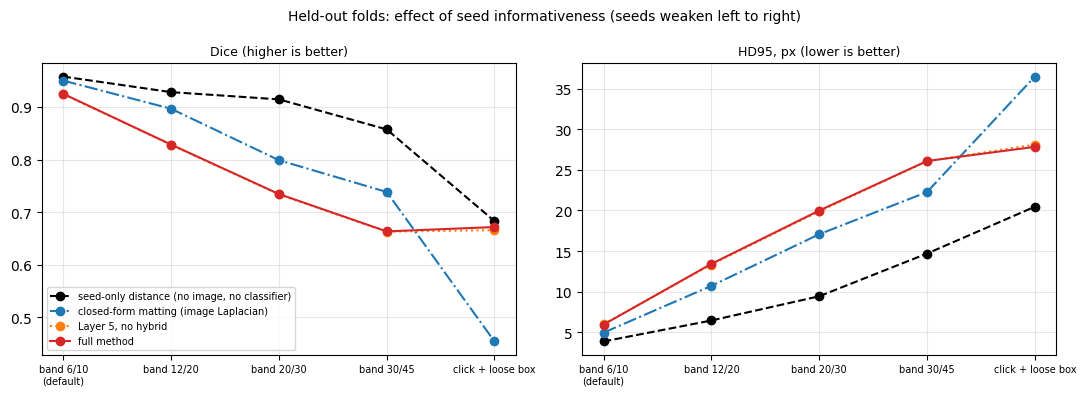

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
styles = {'seed_only_distance': ('k', '--', 'seed-only distance (no image, no classifier)'),
          'closed_form_matting': ('tab:blue', '-.', 'closed-form matting (image Laplacian)'),
          'layer5_no_hybrid': ('tab:orange', ':', 'Layer 5, no hybrid'),
          'full_method': ('tab:red', '-', 'full method')}
x = np.arange(len(order))
for m, (c, ls, lab) in styles.items():
    for k, metric in enumerate(('dice', 'hd95')):
        v = tab[tab['method'] == m].set_index('setting').loc[order][metric].to_numpy()
        ax[k].plot(x, v, color=c, ls=ls, marker='o', label=lab)
for k, t in enumerate(('Dice (higher is better)', 'HD95, px (lower is better)')):
    ax[k].set_xticks(x); ax[k].set_xticklabels([o.replace(' (default)', '\n(default)') for o in order], fontsize=7)
    ax[k].set_title(t, fontsize=9); ax[k].grid(alpha=.3)
ax[0].legend(fontsize=7)
plt.suptitle("Held-out folds: effect of seed informativeness (seeds weaken left to right)", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR, "fig_mias_seed_sweep_K" + str(K_FIXED) + ".png"), dpi=150, bbox_inches='tight'); plt.show()

In [ ]:
def verify_mias3():
    checks = {
        "only the MIAS mass images were scored"          : set(sweep['image_id']) == set(EVAL_TEST),
        "every setting x method x image present"         : len(sweep) == len(SETTINGS) * len(METHODS) * len(EVAL_TEST),
        "same images for every method"                   : sweep.groupby(['setting', 'method'])['image_id'].nunique().nunique() == 1,
        "probability maps are out-of-fold (one test fold per image)": sorted(sum([f['test_ids'] for f in FOLDS], [])) == EVAL_TEST,
        "generated seeds never use the whole mask (>=95%)": gen_strict >= 0.95,
        "metrics finite for >= 99% rows"                 : sweep['dice'].notna().mean() >= 0.99,
        "outputs saved"                                  : all(os.path.exists(os.path.join(OUT_DIR, f)) for f in ("seed_sweep_per_image.csv", "seed_sweep_table.csv", "seed_sweep_ci.csv")),
    }
    print("=" * 56); print(f"MIAS NOTEBOOK 3 VERIFICATION (K = {K_FIXED})"); print("=" * 56); ok = True
    for k, v in checks.items(): print(f"  {'OK  ' if bool(v) else 'FAIL'}  {k}"); ok = ok and bool(v)
    print("=" * 56); return ok
verify_mias3()

MIAS NOTEBOOK 3 VERIFICATION (K = 8)
  OK    only the MIAS mass images were scored
  OK    every setting x method x image present
  OK    same images for every method
  OK    probability maps are out-of-fold (one test fold per image)
  OK    generated seeds never use the whole mask (>=95%)
  OK    metrics finite for >= 99% rows
  OK    outputs saved


True